# Measuring a campaign when not everyone gets treated
### A/B testing with non-compliance: ITT, CACE, power and a go / no-go decision

**Scenario (simulated data).** A multi-site service business wants to know whether a phone call reminding customers to come back increases their return rate. Customers are randomly assigned to a call group or a control group across 12 sites.

The catch: the call centre cannot reach everyone. Many customers assigned to the call group are never contacted, and reachable customers are not a random subset (they tend to be more engaged anyway).

This notebook shows:
1. Why comparing *contacted vs control* gives a biased answer.
2. The **intention-to-treat (ITT)** effect: the effect of *assigning* a call.
3. The **complier average causal effect (CACE)**: the effect of *actually receiving* a call, using random assignment as an instrument.
4. **Power and minimum detectable effect** per site, and how low contact rates dilute them.
5. How to turn the estimated uplift into a **value-per-call** decision.

All data is simulated. Numbers are illustrative.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Simulate the experiment

Each customer has a latent engagement score. It drives both the chance of returning on their own **and** the chance of picking up the phone. That correlation is what makes the naive comparison misleading.

Per site we vary: number of customers, baseline return rate, contact rate and the true effect of a call on customers who receive it.

In [2]:
n_sites = 12
sites = pd.DataFrame({
    "site": [f"S{i+1:02d}" for i in range(n_sites)],
    "n_customers": rng.integers(1500, 6000, n_sites),
    "baseline_return": rng.uniform(0.40, 0.65, n_sites),
    "contact_rate": rng.uniform(0.35, 0.80, n_sites),
    "true_effect_compliers": rng.uniform(0.01, 0.07, n_sites),
})

rows = []
for s in sites.itertuples():
    n = s.n_customers
    engagement = rng.normal(0, 1, n)
    assigned = rng.integers(0, 2, n)  # 1 = call group, 50/50 random split
    # reachability depends on engagement (selection), calibrated to the site's contact rate
    p_reach = 1 / (1 + np.exp(-(np.log(s.contact_rate / (1 - s.contact_rate)) + 0.8 * engagement)))
    reachable = rng.random(n) < p_reach
    called = (assigned == 1) & reachable  # one-sided non-compliance: control never gets a call
    logit_base = np.log(s.baseline_return / (1 - s.baseline_return)) + 0.6 * engagement
    p_return = 1 / (1 + np.exp(-logit_base)) + s.true_effect_compliers * called
    returned = rng.random(n) < np.clip(p_return, 0, 1)
    rows.append(pd.DataFrame({"site": s.site, "assigned": assigned,
                              "called": called.astype(int), "returned": returned.astype(int)}))

df = pd.concat(rows, ignore_index=True)
print(f"{len(df):,} customers across {n_sites} sites")
df.head()

44,225 customers across 12 sites


,site,assigned,called,returned
0,S01,0,0,1
1,S01,0,0,1
2,S01,0,0,0
3,S01,1,0,1
4,S01,1,1,1


## 2. Three ways to compare, pooled across sites

- **Naive (per-protocol):** customers who were called vs control. Biased, because the people we managed to call were more likely to return anyway.
- **ITT:** everyone assigned to the call group vs control, whether or not they were reached. Unbiased for the effect of the *policy*, but diluted by everyone who was never called.
- **CACE (Wald estimator):** ITT divided by the contact rate in the call group. Under random assignment, no calls in the control group and no effect of assignment except through the call, this recovers the effect on customers who actually receive a call.

In [4]:
def estimates(d):
    t, c = d[d.assigned == 1], d[d.assigned == 0]
    naive = d[(d.assigned == 1) & (d.called == 1)].returned.mean() - c.returned.mean()
    itt = t.returned.mean() - c.returned.mean()
    compliance = t.called.mean()
    se_itt = np.sqrt(t.returned.var() / len(t) + c.returned.var() / len(c))
    cace = itt / compliance
    se_cace = se_itt / compliance  # treats compliance as known; fine for a large sample
    return pd.Series({"naive": naive, "itt": itt, "compliance": compliance,
                      "cace": cace, "se_itt": se_itt, "se_cace": se_cace, "n": len(d)})

pooled = estimates(df)
true_pooled = (sites.true_effect_compliers * sites.n_customers * sites.contact_rate).sum() / (sites.n_customers * sites.contact_rate).sum()
print(pooled[["naive", "itt", "compliance", "cace"]].round(4))
print(f"\nApprox. true effect on called customers: {true_pooled:.4f}")

naive        0.077
itt          0.021
compliance   0.601
cace         0.034
dtype: float64

Approx. true effect on called customers: 0.0403


The naive comparison overstates the effect (it mixes the call's impact with the fact that reachable customers are more engaged). ITT understates it per call because it is spread over customers who never got one. CACE is much closer to the true effect, with the remaining gap down to sampling noise.

## 3. Results by site

In [5]:
z90 = stats.norm.ppf(0.95)
by_site = df.groupby("site").apply(estimates, include_groups=False).join(sites.set_index("site"))
by_site["ci_low"] = by_site.cace - z90 * by_site.se_cace
by_site["ci_high"] = by_site.cace + z90 * by_site.se_cace
by_site["p_value"] = 2 * (1 - stats.norm.cdf(np.abs(by_site.itt / by_site.se_itt)))
by_site["significant_90"] = by_site.p_value < 0.10
by_site[["n", "compliance", "itt", "cace", "ci_low", "ci_high", "p_value", "significant_90", "true_effect_compliers"]]

,n,compliance,itt,cace,ci_low,ci_high,p_value,significant_90,true_effect_compliers
site,,,,,,,,,
S01,1901.000,0.708,-0.009,-0.012,-0.064,0.040,0.701,False,0.055
S02,4982.000,0.613,0.032,0.052,0.015,0.090,0.020,True,0.068
S03,4445.000,0.678,0.005,0.008,-0.028,0.044,0.719,False,0.030
S04,3474.000,0.507,0.016,0.032,-0.023,0.087,0.346,False,0.032
S05,3448.000,0.733,0.033,0.045,0.006,0.083,0.055,True,0.038
S06,5363.000,0.721,0.028,0.039,0.009,0.069,0.033,True,0.021
S07,1886.000,0.687,0.063,0.092,0.037,0.146,0.006,True,0.018
S08,4638.000,0.434,0.028,0.065,0.010,0.120,0.051,True,0.039
S09,2406.000,0.569,0.004,0.007,-0.052,0.066,0.839,False,0.024


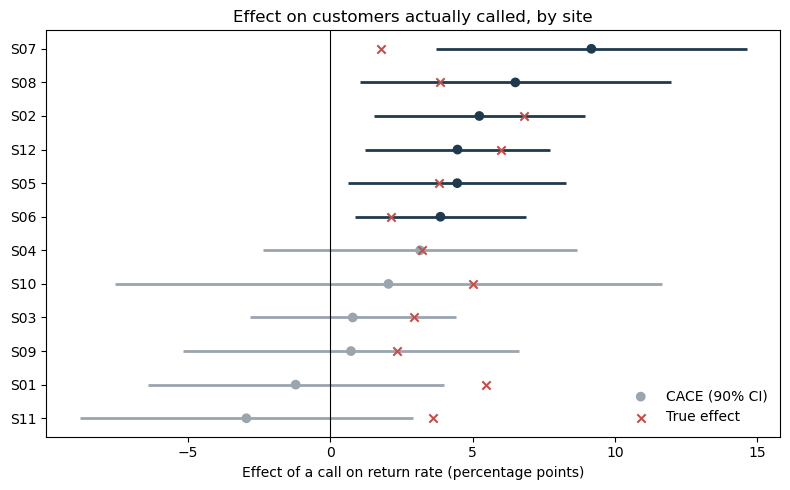

In [6]:
d = by_site.sort_values("cace")
fig, ax = plt.subplots(figsize=(8, 5))
colors = np.where(d.significant_90, "#1F3A4D", "#9AA5AE")
ax.errorbar(d.cace * 100, range(len(d)), xerr=(d.cace - d.ci_low) * 100, fmt="none", ecolor=colors, elinewidth=2)
ax.scatter(d.cace * 100, range(len(d)), c=colors, zorder=3, label="CACE (90% CI)")
ax.scatter(d.true_effect_compliers * 100, range(len(d)), marker="x", color="#C0504D", zorder=4, label="True effect")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(d)), d.index)
ax.set_xlabel("Effect of a call on return rate (percentage points)")
ax.set_title("Effect on customers actually called, by site")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

Some sites with a real positive effect are not significant. That is not evidence the call does nothing there: it is a power problem, which the next section makes explicit.

## 4. Power and minimum detectable effect (MDE)

For a two-arm test on a proportion, the MDE on the ITT scale is roughly

$$MDE_{ITT} = (z_{1-\alpha/2} + z_{1-\beta}) \sqrt{p(1-p)\left(\tfrac{1}{n_t} + \tfrac{1}{n_c}\right)}$$

Since only a share of the call group is reached, the smallest effect *per call* we can detect is $MDE_{ITT}$ divided by the contact rate. Low contact rates inflate it quickly.

In [7]:
def mde(p, n_t, n_c, alpha=0.10, power=0.80):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return z * np.sqrt(p * (1 - p) * (1 / n_t + 1 / n_c))

counts = df.groupby(["site", "assigned"]).size().unstack()
base = df[df.assigned == 0].groupby("site").returned.mean()
power_tbl = pd.DataFrame({
    "baseline": base,
    "compliance": by_site.compliance,
    "mde_itt": [mde(base[s], counts.loc[s, 1], counts.loc[s, 0]) for s in base.index],
})
power_tbl["mde_per_call"] = power_tbl.mde_itt / power_tbl.compliance
power_tbl["true_effect"] = by_site.true_effect_compliers
power_tbl["detectable"] = power_tbl.true_effect >= power_tbl.mde_per_call
power_tbl.sort_values("mde_per_call")

,baseline,compliance,mde_itt,mde_per_call,true_effect,detectable
site,,,,,,
S06,0.627,0.721,0.033,0.046,0.021,False
S12,0.420,0.651,0.032,0.049,0.060,True
S03,0.435,0.678,0.037,0.055,0.030,False
S02,0.588,0.613,0.035,0.057,0.068,True
S05,0.492,0.733,0.042,0.058,0.038,False
S01,0.615,0.708,0.055,0.078,0.055,False
S07,0.537,0.687,0.057,0.083,0.018,False
S08,0.578,0.434,0.036,0.083,0.039,False
S04,0.501,0.507,0.042,0.083,0.032,False


In [8]:
# How many customers per arm would a site need to detect a 3 pp effect per call?
def n_per_arm(p, effect_per_call, compliance, alpha=0.10, power=0.80):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    itt = effect_per_call * compliance
    return int(np.ceil(2 * p * (1 - p) * (z / itt) ** 2))

for c in [0.8, 0.6, 0.4]:
    print(f"contact rate {c:.0%}: {n_per_arm(0.5, 0.03, c):,} customers per arm")

contact rate 80%: 5,367 customers per arm
contact rate 60%: 9,541 customers per arm
contact rate 40%: 21,468 customers per arm


Halving the contact rate roughly **quadruples** the sample needed. Improving call delivery is often worth more than running the test longer.

## 5. From uplift to a decision

A call is worth making where the expected extra returns pay for it:

$$\text{value per call} = CACE \times \text{margin per return} - \text{cost per call}$$

The inputs below are placeholders; in practice they come from finance and operations.

In [9]:
margin_per_return = 40.0   # illustrative
cost_per_call = 1.5        # illustrative

by_site["value_per_call"] = by_site.cace * margin_per_return - cost_per_call
by_site["value_per_call_low"] = by_site.ci_low * margin_per_return - cost_per_call
by_site["decision"] = np.select(
    [by_site.value_per_call_low > 0, by_site.value_per_call > 0],
    ["call: clearly pays off", "call: likely pays off, keep measuring"],
    default="review: no clear return")
by_site[["compliance", "cace", "value_per_call", "value_per_call_low", "decision"]].sort_values("value_per_call", ascending=False)

,compliance,cace,value_per_call,value_per_call_low,decision
site,,,,,
S07,0.687,0.092,2.170,-0.012,"call: likely pays off, keep measuring"
S08,0.434,0.065,1.102,-1.087,"call: likely pays off, keep measuring"
S02,0.613,0.052,0.596,-0.891,"call: likely pays off, keep measuring"
S12,0.651,0.045,0.289,-1.017,"call: likely pays off, keep measuring"
S05,0.733,0.045,0.285,-1.243,"call: likely pays off, keep measuring"
S06,0.721,0.039,0.049,-1.147,"call: likely pays off, keep measuring"
S04,0.507,0.032,-0.237,-2.439,review: no clear return
S10,0.390,0.020,-0.682,-4.519,review: no clear return
S03,0.678,0.008,-1.184,-2.628,review: no clear return


## 6. Takeaways

- **Never compare only the customers you reached against control.** Reachability is not random, and the bias goes in the flattering direction.
- **Report ITT and CACE together.** ITT answers "what does the policy do?"; CACE answers "what does a call do for someone who gets it?". Both matter for different decisions.
- **Check power per segment before reading significance.** A non-significant site with low contact and a small sample says little either way.
- **Translate the effect into money per action.** That turns a statistical result into a go / no-go per site.

**Assumptions behind CACE:** random assignment, no calls in the control group, assignment affects returns only through the call (exclusion restriction), and treatment is recorded correctly. If calls are logged but not made, measured compliance is overstated and CACE is biased towards zero, so delivery data deserves its own validation.